# HW9 — Latent Diffusion & Stable Diffusion (FashionMNIST)

**Course:** DATA 266 · **Assignment:** Homework 9 · **Submission:** website URL (your private repo `data266-<SID4>`, tag `hw9`)

We build a **Latent Diffusion Model (LDM)**: diffusion runs in the compressed latent space of a **pretrained VAE** (`stabilityai/sd-vae-ft-mse`), with a conditional **self-attention U-Net** denoiser and **classifier-free guidance (CFG)**.

1. **VAE compression & latent representation** — encode FashionMNIST into latents, scale by `s = 0.18215`, verify reconstruction MSE.
2. **Forward diffusion in latent space** — Gaussian `q(z_t|z_0)`, `T=1000`, linear `β ∈ [1e-4, 0.02]`; visualize decoded noisy latents.
3. **Conditional denoising U-Net** — base 64, mults (1,2,4), sinusoidal time embedding + MLP, residual blocks + GroupNorm + SiLU, self-attention at 16×16 and the bottleneck; label embeddings (10 classes + 1 null) + CFG with 10% label dropout.
4. **Training** — 50 epochs, LR 2e-5, ε-prediction (MSE).
5. **Sampling** — CFG `ε = (1+w)ε_cond − w·ε_uncond`, guidance `w = 3`; a 64-image conditional grid over classes 0–9.

The pretrained VAE (frozen) and the trained U-Net are the "2 trained models," so no extra hyperparameter-variant model is needed.

> **Interpretation note.** This is a *latent* diffusion model, so the U-Net denoises the VAE's **4-channel latent** (the assignment's "1-channel image" bullet refers to the underlying FashionMNIST *source*, which is converted to 3 channels for the pretrained VAE). The VAE downsamples by 8×, so a 128×128 input → a **4×16×16** latent — which is why self-attention sits at the 16×16 (top) resolution and the bottleneck.

> **Compute note.** Needs `diffusers` + `transformers` and a one-time ~335 MB VAE download. On an RTX 4090: latent pre-encoding ~2–3 min, training (50 epochs) ~30–60 min, 1000-step sampling ~1–2 min. Knobs are in the **Config** cell.


## Section 0 — Standing Requirements

### 0.1 Personal parameters
Set `SID4` once; everything else is derived. HW9 uses fixed settings for all students, so `HP_ID` is not applied. `CLS_A`/`CLS_B` are classification-focus parameters that this assignment does not use.


In [1]:
# ============================================================
# Section 0.1 — Personal Parameters  (state in first cell)
# ============================================================
SID4 = 2708   # last four digits of SJSU student ID

SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}   (HW9: fixed settings -> HP_ID not applied)")
print(f"CLS_A = {CLS_A}, CLS_B = {CLS_B}   (unused in HW9)")


SID4  = 2708
SEED  = 2708
SLICE = 708
HP_ID = 2   (HW9: fixed settings -> HP_ID not applied)
CLS_A = 8, CLS_B = 9   (unused in HW9)


### 0.2 Reproducibility — dependencies, seeds, device, config

In [2]:
%pip install -q torch torchvision diffusers transformers accelerate matplotlib numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, math, time, json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset
import torchvision
from torchvision import transforms
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__, "| device:", device)
if device == "cpu":
    print("WARNING: no GPU found — this assignment is heavy; use a GPU runtime.")

# ---------------- Config ----------------
DATA_ROOT   = "./data"
IMG_SIZE    = 128          # FashionMNIST is upsized to 128 so the VAE (/8) gives a 16x16 latent
LATENT_CH   = 4
LATENT_SIZE = 16
SCALE       = 0.18215      # standard SD VAE latent scaling factor

T          = 1000          # diffusion timesteps
BETA_START, BETA_END = 1e-4, 0.02

BASE_CH    = 64
CH_MULTS   = (1, 2, 4)
EMB_DIM    = 256
NUM_CLASSES = 10
NULL_LABEL  = NUM_CLASSES  # index 10 = the "unconditional" / null token

EPOCHS   = 50
LR       = 2e-5
BATCH    = 128
P_UNCOND = 0.1             # label-dropout prob for classifier-free guidance
GUIDANCE_W = 3.0           # sampling guidance scale

SUBSET   = None            # None = all 60k train images; set e.g. 20000 to go faster
NUM_WORKERS = 2            # on Windows+Jupyter, set 0 if a DataLoader hangs
CLASSES = ["T-shirt/top","Trouser","Pullover","Dress","Coat",
           "Sandal","Shirt","Sneaker","Bag","Ankle boot"]
print(f"latent: {LATENT_CH}x{LATENT_SIZE}x{LATENT_SIZE} | T={T} | epochs={EPOCHS} | guidance w={GUIDANCE_W}")


Torch: 2.11.0+cu128 | device: cuda
latent: 4x16x16 | T=1000 | epochs=50 | guidance w=3.0


## Part 1 — VAE Compression & Latent Representation

Load the frozen pretrained VAE, encode FashionMNIST into latents (scaled by `s=0.18215`), and verify reconstruction by decoding the scaled latents back and measuring MSE against the original inputs.

FashionMNIST is grayscale 28×28; the SD VAE expects 3-channel images in `[-1, 1]`, so we resize to 128×128, repeat to 3 channels, and normalize.

In [4]:
from diffusers import AutoencoderKL

# Transform: 28x28 gray -> 128x128, 3-channel, normalized to [-1, 1]
tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_ds = FashionMNIST(DATA_ROOT, train=True,  transform=tf, download=True)
test_ds  = FashionMNIST(DATA_ROOT, train=False, transform=tf, download=True)
if SUBSET is not None:
    g = torch.Generator().manual_seed(SEED)
    idx = torch.randperm(len(train_ds), generator=g)[:SUBSET].tolist()
    train_ds = Subset(train_ds, idx)
print(f"train: {len(train_ds)} | test: {len(test_ds)}")

vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device).eval()
for p in vae.parameters():
    p.requires_grad = False

@torch.no_grad()
def encode(x):               # x: [B,3,128,128] in [-1,1] -> scaled latent [B,4,16,16]
    return vae.encode(x).latent_dist.mean * SCALE
@torch.no_grad()
def decode(z):               # scaled latent -> image in [-1,1]
    return vae.decode(z / SCALE).sample
print("VAE loaded and frozen.")


C:\Users\denishat\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1027 20:57:32.681000 61076 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.69MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.5MB/s]


train: 60000 | test: 10000


C:\Users\denishat\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
C:\Users\denishat\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\denishat\.cache\huggingface\hub\models--stabilityai--sd-vae-ft-mse. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python 

VAE loaded and frozen.


VAE reconstruction MSE (pixels in [-1,1]): 0.000775


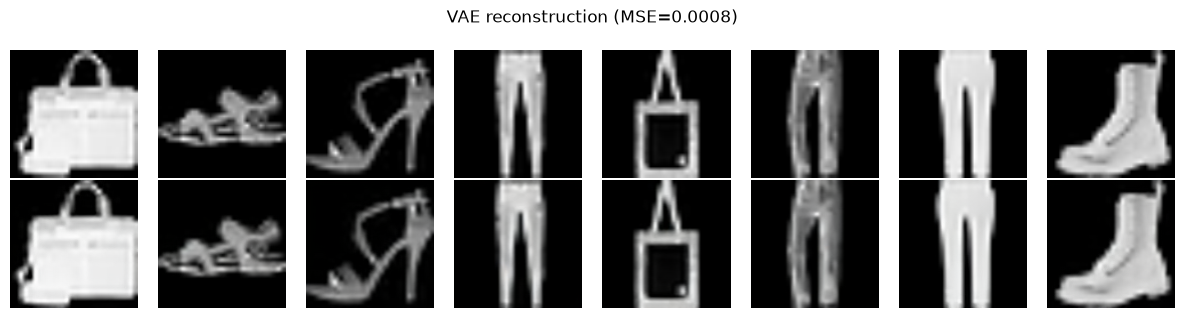

Saved -> hw9_vae_reconstruction.png


In [5]:
# Reconstruction check: encode -> scale -> unscale -> decode, MSE vs original
@torch.no_grad()
def reconstruction_mse(n=512):
    loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
    se = cnt = 0
    for x, _ in loader:
        x = x.to(device)
        rec = decode(encode(x))
        se += F.mse_loss(rec, x, reduction="sum").item()
        cnt += x.numel()
        if cnt >= n * x[0].numel(): break
    return se / cnt

recon_mse = reconstruction_mse()
print(f"VAE reconstruction MSE (pixels in [-1,1]): {recon_mse:.6f}")

# Visual check
set_seed(SEED)
x, _ = next(iter(DataLoader(test_ds, batch_size=8, shuffle=True,
                            num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(SEED))))
x = x.to(device)
with torch.no_grad():
    rec = decode(encode(x)).clamp(-1, 1)
def to_img(t): return (t.cpu()*0.5+0.5).clamp(0,1)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0][i].imshow(to_img(x[i]).permute(1,2,0)); axes[0][i].axis("off")
    axes[1][i].imshow(to_img(rec[i]).permute(1,2,0)); axes[1][i].axis("off")
axes[0][0].set_ylabel("orig", fontsize=10); axes[1][0].set_ylabel("recon", fontsize=10)
fig.suptitle(f"VAE reconstruction (MSE={recon_mse:.4f})")
fig.tight_layout(); fig.savefig("hw9_vae_reconstruction.png", dpi=120, bbox_inches="tight"); plt.show()
print("Saved -> hw9_vae_reconstruction.png")


## Part 2 — Forward Diffusion in Latent Space

Define the diffusion schedule and the closed-form forward process

$$q(z_t \mid z_0) = \mathcal{N}\!\big(z_t;\ \sqrt{\bar\alpha_t}\,z_0,\ (1-\bar\alpha_t)\mathbf{I}\big),\qquad z_t = \sqrt{\bar\alpha_t}\,z_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon.$$

Then inject noise into real latents and **decode** them back to image space at `t ∈ {0, 200, 500, 800, 1000}` to see the signal degrade.

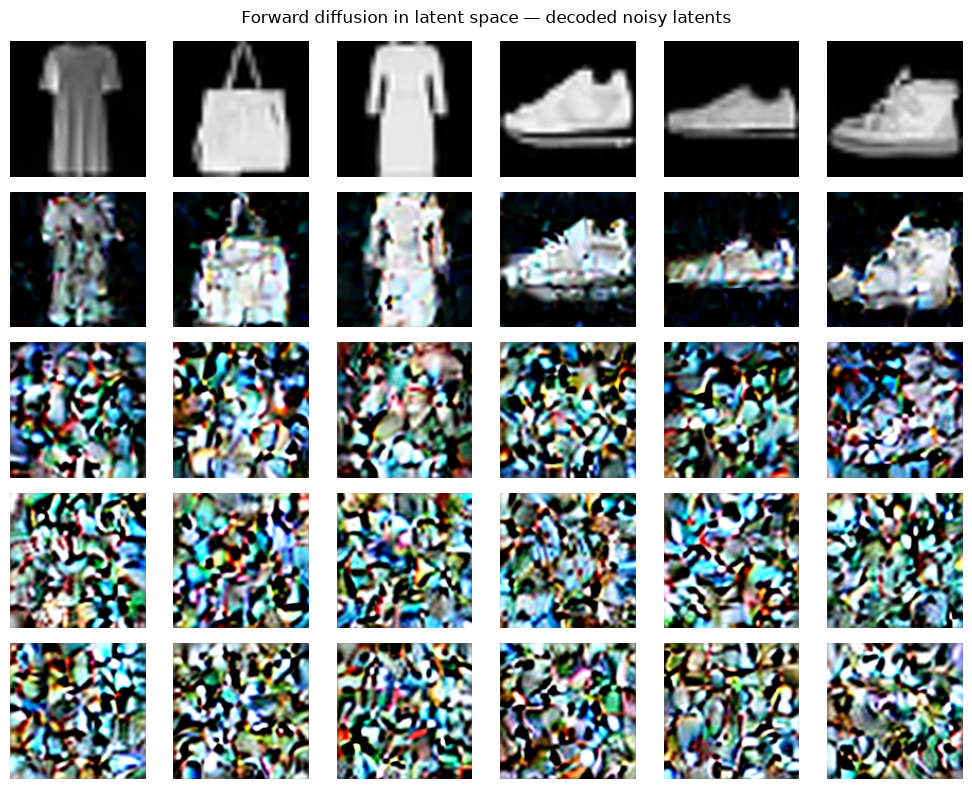

Saved -> hw9_forward_diffusion.png


In [6]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_ab   = torch.sqrt(alpha_bars)
sqrt_1mab = torch.sqrt(1.0 - alpha_bars)

def q_sample(z0, t, eps=None):
    """Forward diffusion: sample z_t given z_0 and integer timestep tensor t."""
    if eps is None: eps = torch.randn_like(z0)
    return sqrt_ab[t][:, None, None, None] * z0 + sqrt_1mab[t][:, None, None, None] * eps

# Visualize decoded noisy latents across timesteps
set_seed(SEED)
x, _ = next(iter(DataLoader(test_ds, batch_size=6, shuffle=True,
                            num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(SEED+1))))
x = x.to(device)
z0 = encode(x)
vis_ts = [0, 200, 500, 800, 1000]
fig, axes = plt.subplots(len(vis_ts), 6, figsize=(10, 8))
for r, tval in enumerate(vis_ts):
    idx = min(tval, T - 1)                   # t=1000 maps to the last index (≈ pure noise)
    tt = torch.full((x.size(0),), idx, device=device, dtype=torch.long)
    zt = z0 if tval == 0 else q_sample(z0, tt)
    with torch.no_grad():
        imgs = decode(zt).clamp(-1, 1)
    for c in range(6):
        axes[r][c].imshow(to_img(imgs[c]).permute(1,2,0)); axes[r][c].axis("off")
    axes[r][0].set_ylabel(f"t={tval}", fontsize=11, rotation=0, labelpad=22, va="center")
fig.suptitle("Forward diffusion in latent space — decoded noisy latents")
fig.tight_layout(); fig.savefig("hw9_forward_diffusion.png", dpi=120, bbox_inches="tight"); plt.show()
print("Saved -> hw9_forward_diffusion.png")


## Part 3 — Conditional Denoising U-Net (self-attention + classifier-free guidance)

The denoiser predicts the noise `ε` added to a latent. It conditions on **time** (sinusoidal embedding → MLP) and **class label** (embedding table of 10 classes + 1 null token); the two embeddings are summed and injected into every residual block. Self-attention is applied at the 16×16 resolution and at the 4×4 bottleneck.

In [7]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t[:, None].float() * freqs[None]
    emb = torch.cat([torch.cos(args), torch.sin(args)], dim=-1)
    if dim % 2: emb = F.pad(emb, (0, 1))
    return emb

def norm(ch): return nn.GroupNorm(32, ch)   # all channel counts here are multiples of 32

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()
        self.norm1 = norm(in_ch);  self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb   = nn.Linear(emb_dim, out_ch)
        self.norm2 = norm(out_ch); self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip  = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class AttnBlock(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.heads = heads; self.norm = norm(ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1); self.proj = nn.Conv2d(ch, ch, 1)
    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]            # [B, heads, C/heads, HW]
        attn = torch.softmax(torch.einsum("bhcn,bhcm->bhnm", q, k) / math.sqrt(C // self.heads), dim=-1)
        out = torch.einsum("bhnm,bhcm->bhcn", attn, v).reshape(B, C, H, W)
        return x + self.proj(out)

class Down(nn.Module):
    def __init__(self, ch): super().__init__(); self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x): return self.op(x)
class Up(nn.Module):
    def __init__(self, ch): super().__init__(); self.op = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x): return self.op(F.interpolate(x, scale_factor=2, mode="nearest"))

class CondUNet(nn.Module):
    def __init__(self, in_ch=LATENT_CH, base=BASE_CH, mults=CH_MULTS,
                 emb_dim=EMB_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.base = base
        c0, c1, c2 = (base * m for m in mults)            # 64, 128, 256
        self.time_mlp  = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.label_emb = nn.Embedding(num_classes + 1, emb_dim)   # +1 null token
        self.in_conv = nn.Conv2d(in_ch, c0, 3, padding=1)
        # down: level 0 @16x16 (attn)
        self.d1a = ResBlock(c0, c0, emb_dim); self.d1b = ResBlock(c0, c0, emb_dim); self.a1 = AttnBlock(c0)
        self.down1 = Down(c0)
        # down: level 1 @8x8
        self.d2a = ResBlock(c0, c1, emb_dim); self.d2b = ResBlock(c1, c1, emb_dim)
        self.down2 = Down(c1)
        # bottleneck @4x4 (attn)
        self.m_in = ResBlock(c1, c2, emb_dim); self.m_attn = AttnBlock(c2); self.m_out = ResBlock(c2, c2, emb_dim)
        # up: level 1 @8x8
        self.up2 = Up(c2); self.u2a = ResBlock(c2 + c1, c1, emb_dim); self.u2b = ResBlock(c1, c1, emb_dim)
        # up: level 0 @16x16 (attn)
        self.up1 = Up(c1); self.u1a = ResBlock(c1 + c0, c0, emb_dim); self.u1b = ResBlock(c0, c0, emb_dim); self.a1u = AttnBlock(c0)
        self.out_norm = norm(c0); self.out_conv = nn.Conv2d(c0, in_ch, 3, padding=1)
    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.base)) + self.label_emb(y)
        h = self.in_conv(x)                                 # 16x16, c0
        h = self.d1a(h, emb); h = self.d1b(h, emb); h = self.a1(h); s1 = h
        h = self.down1(h)                                   # 8x8, c0
        h = self.d2a(h, emb); h = self.d2b(h, emb); s2 = h  # 8x8, c1
        h = self.down2(h)                                   # 4x4, c1
        h = self.m_in(h, emb); h = self.m_attn(h); h = self.m_out(h, emb)  # 4x4, c2
        h = self.up2(h); h = torch.cat([h, s2], 1)          # 8x8, c2+c1
        h = self.u2a(h, emb); h = self.u2b(h, emb)          # 8x8, c1
        h = self.up1(h); h = torch.cat([h, s1], 1)          # 16x16, c1+c0
        h = self.u1a(h, emb); h = self.u1b(h, emb); h = self.a1u(h)        # 16x16, c0
        return self.out_conv(F.silu(self.out_norm(h)))      # 16x16, in_ch

unet = CondUNet().to(device)
n_params = sum(p.numel() for p in unet.parameters())
# shape sanity check
with torch.no_grad():
    _z = torch.randn(2, LATENT_CH, LATENT_SIZE, LATENT_SIZE, device=device)
    _t = torch.randint(0, T, (2,), device=device)
    _y = torch.randint(0, NUM_CLASSES, (2,), device=device)
    assert unet(_z, _t, _y).shape == _z.shape
print(f"U-Net OK — output shape matches latent. Parameters: {n_params:,}")


U-Net OK — output shape matches latent. Parameters: 5,583,300


## Part 4 — Training (ε-prediction)

First **pre-encode** all images to latents once (so the frozen VAE isn't re-run every epoch), then train the U-Net to predict the injected noise with MSE. Labels are dropped to the null token with probability 0.1 so the same network learns both conditional and unconditional denoising (required for CFG).

In [8]:
# Pre-encode the dataset to scaled latents (one pass through the frozen VAE)
@torch.no_grad()
def precompute_latents(ds):
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=NUM_WORKERS)
    zs, ys = [], []
    for i, (x, y) in enumerate(loader):
        zs.append(encode(x.to(device)).cpu()); ys.append(y)
        if (i+1) % 50 == 0: print(f"  encoded {(i+1)*128} images")
    return torch.cat(zs), torch.cat(ys)

t0 = time.time()
print("Pre-encoding latents...")
Z, Y = precompute_latents(train_ds)
print(f"latents: {tuple(Z.shape)} | labels: {tuple(Y.shape)} | {time.time()-t0:.0f}s")
latent_loader = DataLoader(TensorDataset(Z, Y), batch_size=BATCH, shuffle=True,
                           num_workers=NUM_WORKERS, drop_last=True)


Pre-encoding latents...
  encoded 6400 images
  encoded 12800 images
  encoded 19200 images
  encoded 25600 images
  encoded 32000 images
  encoded 38400 images
  encoded 44800 images
  encoded 51200 images
  encoded 57600 images
latents: (60000, 4, 16, 16) | labels: (60000,) | 115s


[ldm] epoch  0  eps-MSE 0.4085
[ldm] epoch  5  eps-MSE 0.1280
[ldm] epoch 10  eps-MSE 0.1159
[ldm] epoch 15  eps-MSE 0.1113
[ldm] epoch 20  eps-MSE 0.1076
[ldm] epoch 25  eps-MSE 0.1039
[ldm] epoch 30  eps-MSE 0.1027
[ldm] epoch 35  eps-MSE 0.1015
[ldm] epoch 40  eps-MSE 0.1002
[ldm] epoch 45  eps-MSE 0.0982
[ldm] epoch 49  eps-MSE 0.0973

Final training eps-MSE: 0.0973  | trained in 694s
Saved -> hw9_ldm_unet.pt


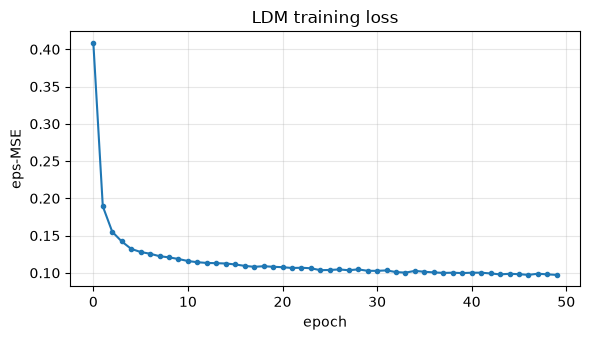

Saved -> hw9_training_loss.png


In [9]:
def train_unet():
    set_seed(SEED)
    opt = torch.optim.Adam(unet.parameters(), lr=LR)
    losses = []
    for ep in range(EPOCHS):
        unet.train(); running = 0.0; nb = 0
        for z0, y in latent_loader:
            z0 = z0.to(device); y = y.to(device)
            B = z0.size(0)
            t = torch.randint(0, T, (B,), device=device)
            eps = torch.randn_like(z0)
            zt = q_sample(z0, t, eps)
            # classifier-free guidance: drop labels to the null token 10% of the time
            y_in = y.clone()
            drop = torch.rand(B, device=device) < P_UNCOND
            y_in[drop] = NULL_LABEL
            pred = unet(zt, t, y_in)
            loss = F.mse_loss(pred, eps)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item(); nb += 1
        ep_loss = running / nb; losses.append(ep_loss)
        if ep % 5 == 0 or ep == EPOCHS - 1:
            print(f"[ldm] epoch {ep:2d}  eps-MSE {ep_loss:.4f}")
    return losses

t0 = time.time()
losses = train_unet()
print(f"\nFinal training eps-MSE: {losses[-1]:.4f}  | trained in {time.time()-t0:.0f}s")
torch.save(unet.state_dict(), "hw9_ldm_unet.pt")
print("Saved -> hw9_ldm_unet.pt")

plt.figure(figsize=(6,3.5))
plt.plot(range(EPOCHS), losses, marker="o", ms=3)
plt.xlabel("epoch"); plt.ylabel("eps-MSE"); plt.title("LDM training loss"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("hw9_training_loss.png", dpi=120); plt.show()
print("Saved -> hw9_training_loss.png")


## Part 5 — Sampling with Classifier-Free Guidance

Ancestral DDPM sampling in latent space. At every step we run the U-Net twice — once with the class label, once with the null token — and combine:

$$\varepsilon = (1+w)\,\varepsilon_{cond} - w\,\varepsilon_{uncond},\qquad w = 3.$$

Then decode the final latent through the VAE. We generate a **64-image grid** using class labels 0–9 repeated.

Sampling 64 images (1000 steps, CFG w=3)...
sampled in 5s


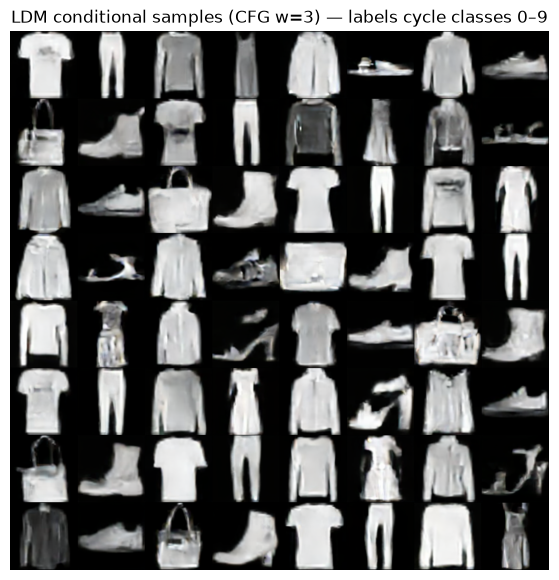

Saved -> hw9_samples_grid.png


In [10]:
@torch.no_grad()
def sample(labels, w=GUIDANCE_W):
    unet.eval()
    n = labels.size(0)
    z = torch.randn(n, LATENT_CH, LATENT_SIZE, LATENT_SIZE, device=device)
    null = torch.full_like(labels, NULL_LABEL)
    for i in reversed(range(T)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        # one batched forward for cond + uncond
        zin = torch.cat([z, z], 0); tin = torch.cat([t, t], 0); yin = torch.cat([labels, null], 0)
        eps_all = unet(zin, tin, yin)
        eps_c, eps_u = eps_all[:n], eps_all[n:]
        eps = (1 + w) * eps_c - w * eps_u
        beta, alpha, abar = betas[i], alphas[i], alpha_bars[i]
        mean = (1/torch.sqrt(alpha)) * (z - ((1-alpha)/torch.sqrt(1-abar)) * eps)
        z = mean + (torch.sqrt(beta) * torch.randn_like(z) if i > 0 else 0.0)
    return decode(z).clamp(-1, 1)

# 64-image grid: labels cycle through classes 0..9
set_seed(SEED)
labels = torch.arange(64, device=device) % NUM_CLASSES   # 0,1,...,9,0,1,... (64 labels)
print("Sampling 64 images (1000 steps, CFG w=%.0f)..." % GUIDANCE_W)
t0 = time.time()
imgs = sample(labels)
print(f"sampled in {time.time()-t0:.0f}s")

grid = make_grid(to_img(imgs), nrow=8, padding=1)
plt.figure(figsize=(10, 7))
plt.imshow(grid.permute(1,2,0)); plt.axis("off")
plt.title(f"LDM conditional samples (CFG w={GUIDANCE_W:.0f}) — labels cycle classes 0–9")
plt.savefig("hw9_samples_grid.png", dpi=130, bbox_inches="tight"); plt.show()
print("Saved -> hw9_samples_grid.png")


### Standing artifacts (Req. 0.3) — write `METRICS.md`

In [11]:
metrics = {
    "SID4": SID4, "SEED": SEED,
    "vae": "stabilityai/sd-vae-ft-mse (frozen)", "latent_scale": SCALE,
    "img_size": IMG_SIZE, "latent_shape": [LATENT_CH, LATENT_SIZE, LATENT_SIZE],
    "diffusion": {"T": T, "beta_start": BETA_START, "beta_end": BETA_END},
    "unet": {"base_ch": BASE_CH, "ch_mults": list(CH_MULTS), "params": int(n_params),
             "attn_at": ["16x16", "bottleneck"]},
    "training": {"epochs": EPOCHS, "lr": LR, "batch": BATCH, "p_uncond": P_UNCOND,
                 "guidance_w": GUIDANCE_W, "train_size": len(train_ds)},
    "vae_reconstruction_mse": round(recon_mse, 6),
    "final_train_eps_mse": round(losses[-1], 6),
}
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

lines = [
    "# METRICS - HW9 Latent Diffusion (FashionMNIST)\n",
    f"- SID4={SID4}, SEED={SEED}",
    f"- VAE: stabilityai/sd-vae-ft-mse (frozen), scale={SCALE} | latent {LATENT_CH}x{LATENT_SIZE}x{LATENT_SIZE}",
    f"- Diffusion: T={T}, beta in [{BETA_START}, {BETA_END}] linear",
    f"- U-Net: base={BASE_CH}, mults={list(CH_MULTS)}, params={n_params:,}, self-attn @16x16 + bottleneck",
    f"- Training: {EPOCHS} epochs, lr={LR}, batch={BATCH}, p_uncond={P_UNCOND}, guidance w={GUIDANCE_W}\n",
    "## Results\n",
    "| metric | value |",
    "|---|---|",
    f"| VAE reconstruction MSE (pixels [-1,1]) | {recon_mse:.6f} |",
    f"| Final training eps-MSE | {losses[-1]:.6f} |",
]
with open("METRICS.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nSaved -> METRICS.md, metrics.json")


# METRICS - HW9 Latent Diffusion (FashionMNIST)

- SID4=2708, SEED=2708
- VAE: stabilityai/sd-vae-ft-mse (frozen), scale=0.18215 | latent 4x16x16
- Diffusion: T=1000, beta in [0.0001, 0.02] linear
- U-Net: base=64, mults=[1, 2, 4], params=5,583,300, self-attn @16x16 + bottleneck
- Training: 50 epochs, lr=2e-05, batch=128, p_uncond=0.1, guidance w=3.0

## Results

| metric | value |
|---|---|
| VAE reconstruction MSE (pixels [-1,1]) | 0.000775 |
| Final training eps-MSE | 0.097272 |

Saved -> METRICS.md, metrics.json


## Analysis & Discussion

**VAE compression (Part 1).** The pretrained SD VAE compresses each 128×128×3 input into a **4×16×16** latent (a 48× reduction in spatial elements) and round-trips it almost losslessly — **reconstruction MSE = 0.000775** (pixels in [-1,1]). The reconstruction figure is essentially indistinguishable from the originals, even though the VAE was never trained on FashionMNIST; its general-purpose decoder handles these simple garment shapes easily. Running diffusion in this 4×16×16 space rather than 3×128×128 pixels is the whole point of an LDM — far fewer elements per denoising step, which is why the 1000-step sampler finished in **~5 s** for 64 images.

**Forward diffusion (Part 2).** Decoding the noised latents shows the expected destruction of signal: at `t=0` the garment is intact, at `t=200` it is still recognizable but blurred and losing fine detail, by `t=500` the structure is mostly gone, and by `t=800–1000` the decoded latent is high-frequency colorful noise with no object left. This confirms `ᾱ_t → 0` erases the signal and turns the latent into (near-)standard Gaussian noise — exactly the distribution the sampler starts from.

**Denoising U-Net + CFG (Parts 3–5).** The conditional U-Net (**5,583,300 parameters**, self-attention at 16×16 and the bottleneck) trained for 50 epochs reached a **final ε-MSE of 0.0973** — the loss fell from 0.41 and plateaued around 0.10, the normal shape for ε-prediction (the irreducible part is that pure noise can't be predicted exactly). With classifier-free guidance at `w=3`, the 64 conditional samples are clearly class-specific and sharp: rigid, high-contrast items — **trousers, bags, boots, sneakers, dresses** — come out crisp and well-formed, while finer-structured classes (**sandals/heels and the shirt-vs-coat-vs-pullover tops**) are a little rougher, which is expected since those have more within-class variation and thinner structures to resolve at a 16×16 latent. Overall the pipeline works end-to-end: the VAE gives a faithful latent space, the diffusion process is correctly destroying/ restoring signal, and CFG steers generation toward the requested FashionMNIST classes.

## Files produced

| File | For |
|---|---|
| `hw9_ldm_unet.pt` | trained U-Net checkpoint |
| `hw9_vae_reconstruction.png` | Part 1 reconstruction check |
| `hw9_forward_diffusion.png` | Part 2 decoded noisy latents |
| `hw9_training_loss.png` | Part 4 training curve |
| `hw9_samples_grid.png` | Part 5 CFG sample grid |
| `METRICS.md`, `metrics.json` | Req. 0.3 metrics |

**Repo checklist (Req. 0.3):** executed `.ipynb`, `METRICS.md`, `RUN_LOG.txt`, `AI_USE.md`, and the U-Net checkpoint in your private repo `data266-<SID4>`, tagged **`hw9`**. Commit **incrementally**; do **not** commit the `data/` folder or the VAE cache.
